# PathSnap: XGBoost with six features

Use `PathSnap_shared6.zip`, which already contains the engineered features, labels and fixed trip folds. Put it in MyDrive and run all on Colab. Raw GPS preprocessing is already complete.

Scores use geometric weak labels rather than verified per-GPS truth. Distance and heading also help construct these labels, so scores may be optimistic.

## Setup

If Colab requests a restart after installation, restart and run all again.

In [1]:
%pip -q install numpy==2.4.6 pandas==2.2.3 scipy==1.16.3 scikit-learn==1.6.1 joblib==1.6.0 xgboost==3.4.1

In [2]:
from dataclasses import dataclass
from pathlib import Path
from time import perf_counter
import json
import shutil
import zipfile
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from IPython.display import display

FEATURES = ["distance_m", "distance_rank", "heading_difference_deg",
            "projection_fraction", "segment_length_m", "displacement_m"]
METRICS = ["Accuracy", "Precision", "Recall", "F1", "Log Loss",
           "Top-1 Accuracy", "Candidate Miss Rate", "Train Time", "Inference Time"]
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Input

In [3]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive")
INPUT_ZIP = PROJECT_ROOT / "PathSnap_ip" / "PathSnap_shared6.zip"
DATA_ROOT = PROJECT_ROOT / "PathSnap_shared6"
OUTPUT_DIR = PROJECT_ROOT / "output" / "XGBoost_shared6"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required = ["shared_inputs.npz", "train_observations.csv.gz", "student_test_observations.csv.gz",
            "shared_protocol.json", "feature_schema.json", "fold_assignments.csv"]
required += [f"fold_{fold}_indices.npz" for fold in range(1, 6)]
if not all((DATA_ROOT / name).is_file() for name in required):
    if not INPUT_ZIP.is_file():
        raise FileNotFoundError(f"Upload PathSnap_shared6.zip to {INPUT_ZIP.parent}, or edit INPUT_ZIP.")
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(INPUT_ZIP) as archive:
        for name in required:
            with archive.open(name) as source, (DATA_ROOT / name).open("wb") as target:
                shutil.copyfileobj(source, target)
print("Input:", DATA_ROOT)
print("Output:", OUTPUT_DIR)

Mounted at /content/drive
Input: /content/drive/MyDrive/PathSnap_shared6
Output: /content/drive/MyDrive/output/XGBoost_shared6


## Load prepared data

Use the raw six-feature matrices. The globally scaled matrices are not used for CV.

In [4]:
@dataclass
class Dataset:
    candidates: pd.DataFrame
    observations: pd.DataFrame

def load_split(data, split, prefix):
    X = data[f"X_{prefix}_raw"]
    if X.ndim != 2 or X.shape[1] != 6 or not np.isfinite(X).all():
        raise ValueError(f"Invalid six-feature matrix for {split}")
    candidates = pd.DataFrame(X, columns=FEATURES)
    candidates["label"] = data[f"y_{prefix}"]
    for column in ("trip_id", "observation_id", "arc_id"):
        candidates[column] = data[f"{prefix}_{column}"]
    observations = pd.read_csv(DATA_ROOT / f"{split}_observations.csv.gz", dtype={"trip_id": str})
    if not observations.observation_id.is_unique or set(candidates.label.unique()) != {0, 1}:
        raise ValueError(f"Invalid observation IDs or labels in {split}")
    reference = observations.set_index("observation_id")
    assert candidates.observation_id.isin(reference.index).all()
    assert (candidates.trip_id == candidates.observation_id.map(reference.trip_id)).all()
    assert np.array_equal(candidates.label, (candidates.arc_id == candidates.observation_id.map(reference.reference_arc_id)).astype(np.int8))
    positives = candidates.groupby("observation_id").label.sum().reindex(reference.index, fill_value=0)
    assert (positives <= 1).all()
    assert np.array_equal(positives > 0, reference.reference_present)
    return Dataset(candidates, observations)

In [5]:
protocol = json.loads((DATA_ROOT / "shared_protocol.json").read_text())
assert protocol["features"] == FEATURES
with np.load(DATA_ROOT / "shared_inputs.npz", allow_pickle=False) as data:
    assert data["features"].tolist() == FEATURES
    train = load_split(data, "train", "train")
    test = load_split(data, "student_test", "test")
    row_folds = data["fold_id"].copy()

assignments = pd.read_csv(DATA_ROOT / "fold_assignments.csv", dtype={"trip_id": str})
assert assignments.trip_id.is_unique and len(assignments) == 80
trip_folds = assignments.set_index("trip_id").fold
assert set(trip_folds) == {1, 2, 3, 4, 5}
assert np.array_equal(train.candidates.trip_id.map(trip_folds), row_folds)
assert set(train.observations.trip_id) == set(trip_folds.index)
assert train.observations.trip_id.nunique() == 80 and test.observations.trip_id.nunique() == 10
assert not set(train.observations.trip_id) & set(test.observations.trip_id)
assert len(train.candidates) == protocol["train_candidates"]
assert len(test.candidates) == protocol["test_candidates"]

counts = pd.DataFrame([
    {"Split": split, "Trips": d.observations.trip_id.nunique(), "GPS points": len(d.observations),
     "Candidates": len(d.candidates), "Candidate misses": int((~d.observations.reference_present).sum())}
    for split, d in [("train", train), ("student_test", test)]
])
display(counts)
display(pd.read_json(DATA_ROOT / "feature_schema.json"))
counts.to_csv(OUTPUT_DIR / "dataset_counts.csv", index=False)
for name in ["shared_protocol.json", "feature_schema.json", "fold_assignments.csv"]:
    shutil.copy2(DATA_ROOT / name, OUTPUT_DIR / name)

,Split,Trips,GPS points,Candidates,Candidate misses
0,train,80,208417,1241756,23068
1,student_test,10,19160,125525,48


,name,definition,rationale
0,distance_m,Shortest projected GPS-to-segment distance (me...,Measures spatial compatibility.
1,distance_rank,1-based distance rank; equal distances break b...,Expresses relative proximity among candidates.
2,heading_difference_deg,Absolute wrapped movement/segment heading diff...,Distinguishes opposite travel directions.
3,projection_fraction,Clipped fraction along segment of the perpendi...,Identifies endpoint and interior projections.
4,segment_length_m,Length of the directed straight segment (metres).,Distinguishes short connectors from long roads.
5,displacement_m,Projected displacement from the preceding reta...,Describes movement magnitude and GPS noise.


## Evaluation

Candidate classification uses threshold 0.5. Top-1 includes every GPS point, including candidate misses. Rates are fractions; times are seconds.

In [6]:
def evaluate_predictions(dataset, probabilities, train_seconds=0.0, inference_seconds=0.0):
    c, obs = (dataset.candidates, dataset.observations)
    p = np.asarray(probabilities, dtype=np.float64)
    if p.shape != (len(c),) or not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('Expected one finite probability in [0, 1] per candidate')
    if c.empty:
        raise ValueError('No candidate rows in evaluation partition; classification metrics undefined')
    y, pred = (c.label.to_numpy(), (p >= 0.5).astype(np.int8))
    scored = c[['observation_id', 'arc_id', 'distance_rank']].copy()
    scored['probability'] = p
    best = scored.sort_values(['observation_id', 'probability', 'distance_rank', 'arc_id'], ascending=[True, False, True, True], kind='stable').drop_duplicates('observation_id')
    per_obs = obs.merge(best[['observation_id', 'arc_id', 'probability']], on='observation_id', how='left', validate='one_to_one')
    per_obs.rename(columns={'arc_id': 'predicted_arc_id', 'probability': 'predicted_probability'}, inplace=True)
    per_obs['top1_correct'] = per_obs.predicted_arc_id == per_obs.reference_arc_id
    covered = per_obs.reference_present.astype(bool)
    matrix = confusion_matrix(y, pred, labels=[0, 1])
    scores = dict(zip(METRICS, [float(accuracy_score(y, pred)), float(precision_score(y, pred, zero_division=0)), float(recall_score(y, pred, zero_division=0)), float(f1_score(y, pred, zero_division=0)), float(log_loss(y, np.column_stack([1 - p, p]), labels=[0, 1])), float(per_obs.top1_correct.mean()), float((~covered).mean()), float(train_seconds), float(inference_seconds)]))
    return (scores, matrix, per_obs)

def save_matrix(path, matrix):
    pd.DataFrame(matrix, index=["actual_0", "actual_1"],
                 columns=["predicted_0", "predicted_1"]).to_csv(path)

## XGBoost

Use the shared StandardScaler procedure: fit only on the training partition of each fold. The final scaler sees all 80 training trips. No tuning.

In [7]:
XGBOOST_PARAMS = dict(
    objective="binary:logistic", eval_metric="logloss",
    n_estimators=200, learning_rate=0.05, max_depth=6,
    min_child_weight=10, reg_lambda=1.0, tree_method="hist",
    random_state=RANDOM_STATE, n_jobs=4,
)

def make_model():
    return Pipeline([("scaler", StandardScaler()),
                     ("xgboost", XGBClassifier(**XGBOOST_PARAMS))])

## Cross-validation

Use the five provided index files without generating new splits. Fit times include scaling; prediction times include its transform.

In [8]:
def run_cv(train, row_folds):
    rows = []
    total_matrix = np.zeros((2, 2), dtype=int)
    for fold in range(1, 6):
        with np.load(DATA_ROOT / f"fold_{fold}_indices.npz", allow_pickle=False) as indices:
            fit_idx, valid_idx = indices["fit_idx"], indices["valid_idx"]
        assert np.array_equal(fit_idx, np.flatnonzero(row_folds != fold))
        assert np.array_equal(valid_idx, np.flatnonzero(row_folds == fold))
        fit = train.candidates.iloc[fit_idx]
        valid = train.candidates.iloc[valid_idx]
        valid_trips = trip_folds.index[trip_folds == fold]
        assert not set(fit.trip_id) & set(valid.trip_id)
        assert set(fit.label.unique()) == {0, 1}
        valid_data = Dataset(valid, train.observations.loc[train.observations.trip_id.isin(valid_trips)])
        model = make_model()
        start = perf_counter()
        model.fit(fit[FEATURES], fit.label)
        train_time = perf_counter() - start
        start = perf_counter()
        probabilities = model.predict_proba(valid[FEATURES])[:, 1]
        inference_time = perf_counter() - start
        scores, matrix, _ = evaluate_predictions(valid_data, probabilities, train_time, inference_time)
        rows.append({"Fold": fold, **scores})
        total_matrix += matrix
        print(f"Fold {fold}: F1={scores['F1']:.4f}, Top-1={scores['Top-1 Accuracy']:.4f}")
    metrics = pd.DataFrame(rows)
    summary = metrics[METRICS].agg(["mean", "std"]).T
    summary.index.name = "Metric"
    metrics.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv", index=False)
    summary.to_csv(OUTPUT_DIR / "cv_summary.csv")
    save_matrix(OUTPUT_DIR / "cv_confusion_matrix.csv", total_matrix)
    return metrics, summary

In [9]:
cv_metrics, cv_summary = run_cv(train, row_folds)
display(cv_metrics)
display(cv_summary)

Fold 1: F1=0.7438, Top-1=0.4530
Fold 2: F1=0.7565, Top-1=0.7619
Fold 3: F1=0.7595, Top-1=0.7684
Fold 4: F1=0.8307, Top-1=0.7881
Fold 5: F1=0.7862, Top-1=0.7849


,Fold,Accuracy,Precision,Recall,F1,Log Loss,Top-1 Accuracy,Candidate Miss Rate,Train Time,Inference Time
0,1,0.935200,0.754679,0.733216,0.743793,0.156948,0.453039,0.413778,11.640288,0.440058
1,2,0.925256,0.767966,0.745339,0.756483,0.171713,0.761925,0.016867,9.842253,0.621363
2,3,0.915582,0.774188,0.745407,0.759525,0.183077,0.768407,0.001030,11.086302,0.538393
3,4,0.954935,0.836190,0.825268,0.830693,0.111785,0.788082,0.097955,9.623527,0.678333
4,5,0.938424,0.808874,0.764729,0.786182,0.147854,0.784906,0.023697,9.834005,0.642049


,mean,std
Metric,,
Accuracy,0.933879,0.014789
Precision,0.788379,0.033391
Recall,0.762792,0.036703
F1,0.775335,0.034578
Log Loss,0.154275,0.027329
Top-1 Accuracy,0.711272,0.144773
Candidate Miss Rate,0.110665,0.173508
Train Time,10.405275,0.900490
Inference Time,0.584039,0.095477


## Student test

In [10]:
model = make_model()
# Train on all 80 trips, then evaluate the ten held-out trips once.
start = perf_counter()
model.fit(train.candidates[FEATURES], train.candidates.label)
train_time = perf_counter() - start
start = perf_counter()
probabilities = model.predict_proba(test.candidates[FEATURES])[:, 1]
inference_time = perf_counter() - start
scores, matrix, predictions = evaluate_predictions(test, probabilities, train_time, inference_time)
comparison = pd.DataFrame([{"Model": "XGBoost", **scores}], columns=["Model"] + METRICS)
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
save_matrix(OUTPUT_DIR / "student_test_confusion_matrix.csv", matrix)
model.named_steps["xgboost"].save_model(OUTPUT_DIR / "xgboost_model.ubj")
joblib.dump(model.named_steps["scaler"], OUTPUT_DIR / "final_scaler.joblib")
config = {"parameters": XGBOOST_PARAMS, "features": FEATURES, "threshold": 0.5,
          "preprocessing": "Apply final_scaler.joblib before using the saved XGBoost model"}
(OUTPUT_DIR / "model_config.json").write_text(json.dumps(config, indent=2))
display(comparison)
print("CV confusion matrix: rows actual, columns predicted")
display(pd.read_csv(OUTPUT_DIR / "cv_confusion_matrix.csv", index_col=0))
print("Student-test confusion matrix: rows actual, columns predicted")
display(pd.read_csv(OUTPUT_DIR / "student_test_confusion_matrix.csv", index_col=0))

,Model,Accuracy,Precision,Recall,F1,Log Loss,Top-1 Accuracy,Candidate Miss Rate,Train Time,Inference Time
0,XGBoost,0.943047,0.820844,0.800701,0.810648,0.136986,0.825,0.002505,14.715023,0.570784


CV confusion matrix: rows actual, columns predicted


,predicted_0,predicted_1
actual_0,1018858,37549
actual_1,43718,141631


Student-test confusion matrix: rows actual, columns predicted


,predicted_0,predicted_1
actual_0,103073,3340
actual_1,3809,15303


## Download results

Fold 1: Macro F1 = 0.8534
Fold 2: Macro F1 = 0.8562
Fold 3: Macro F1 = 0.8542
Fold 4: Macro F1 = 0.9024
Fold 5: Macro F1 = 0.8751

XGBOOST RESULTS


,Model,CV Macro F1,CV Macro F1 SD,Student Top-1,Student Macro F1,CV Log Loss,Student Log Loss
0,XGBoost,0.868229,0.021072,0.825,0.888565,0.154275,0.136986


,mean,std
Accuracy,0.933879,0.014789
Precision,0.788379,0.033391
Recall,0.762792,0.036703
F1,0.775335,0.034578
Log Loss,0.154275,0.027329
Top-1 Accuracy,0.711272,0.144773
Candidate Miss Rate,0.110665,0.173508
Train Time,10.405275,0.900490
Inference Time,0.584039,0.095477
Macro F1,0.868229,0.021072


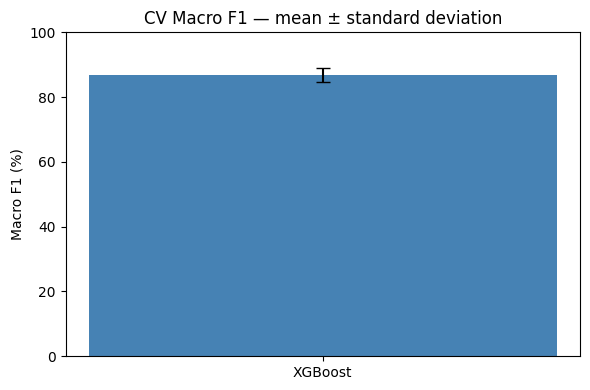

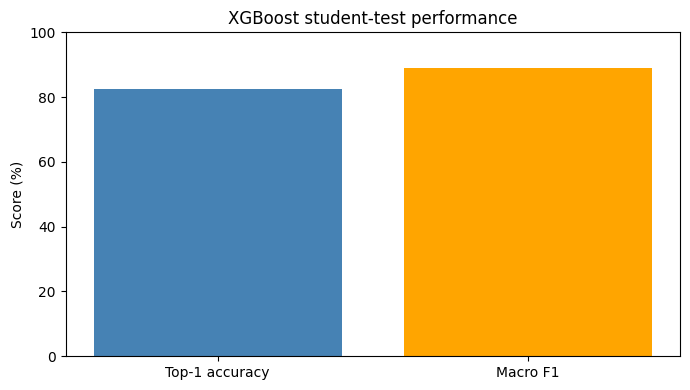

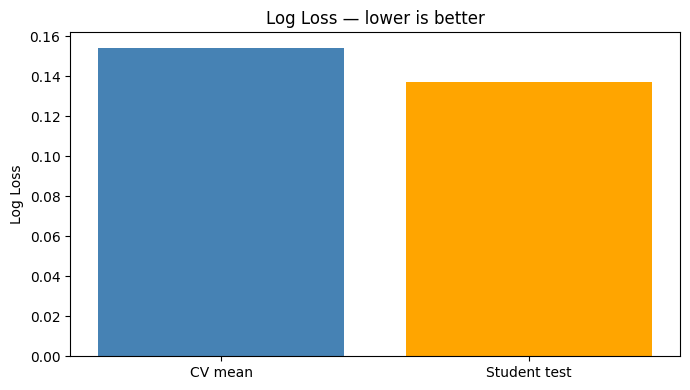

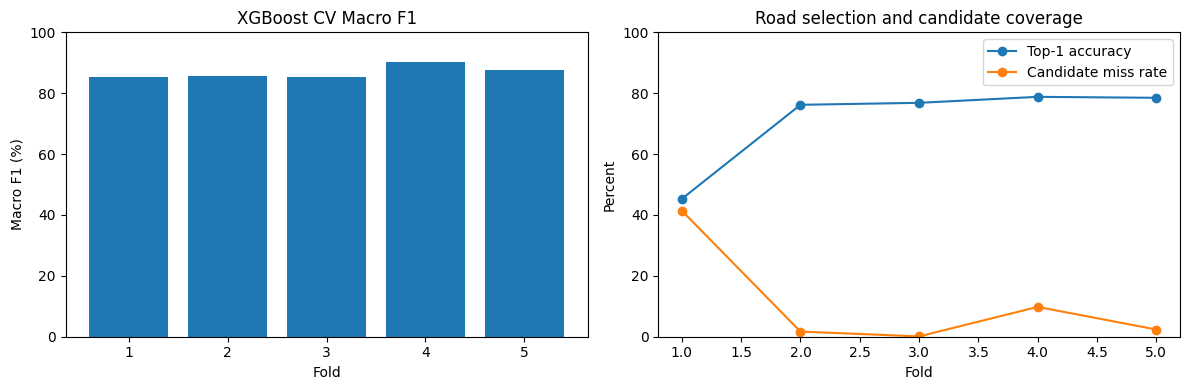

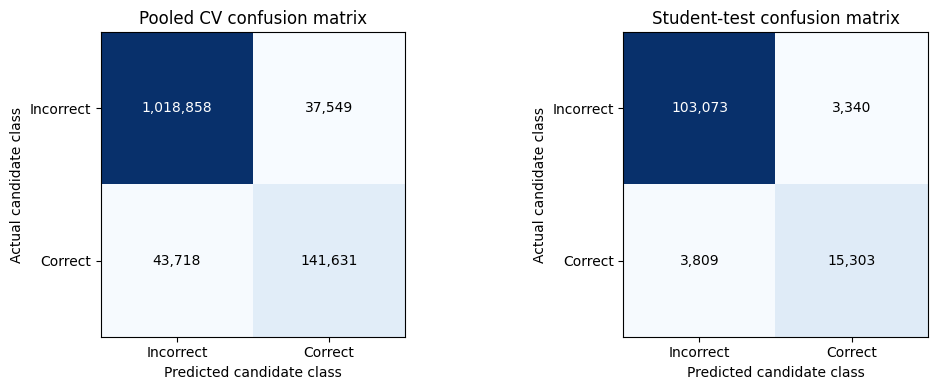

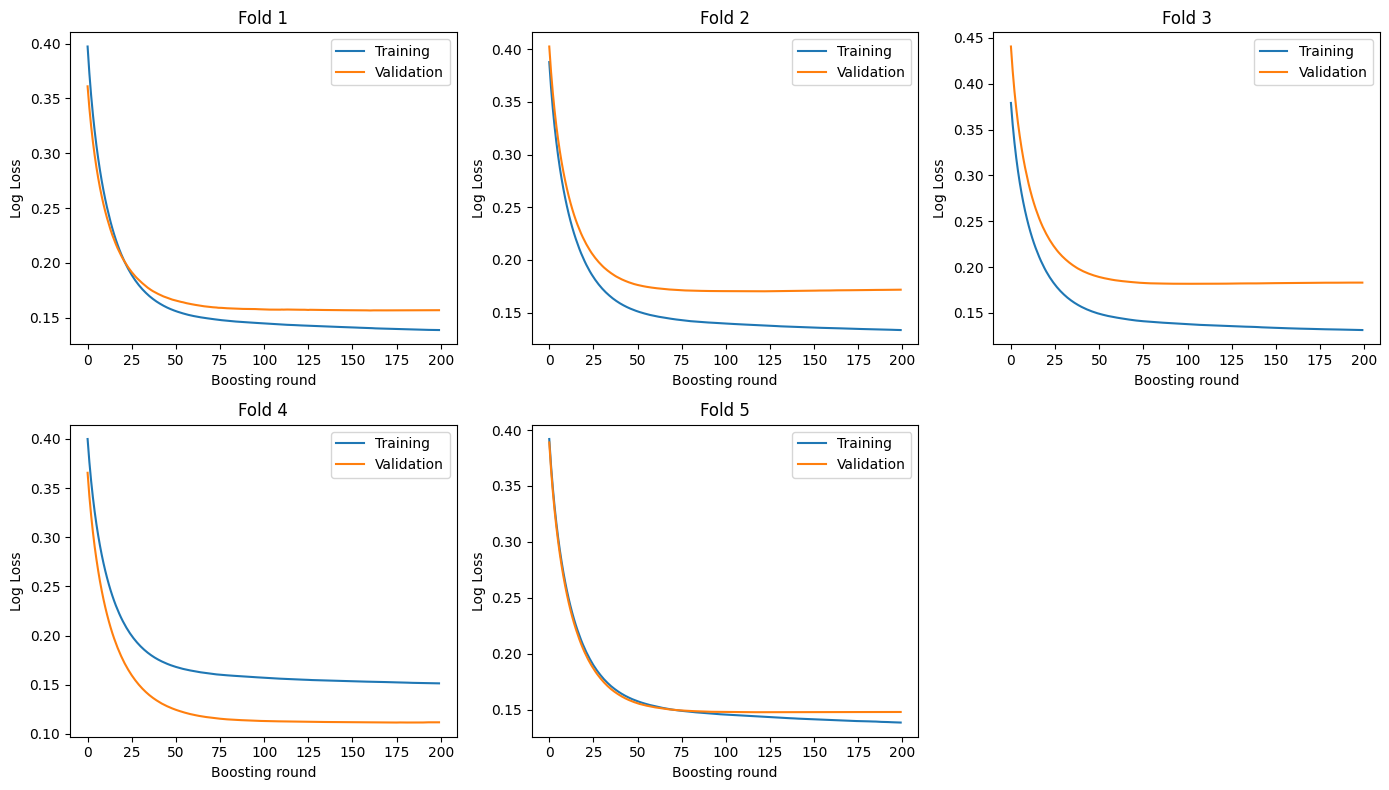

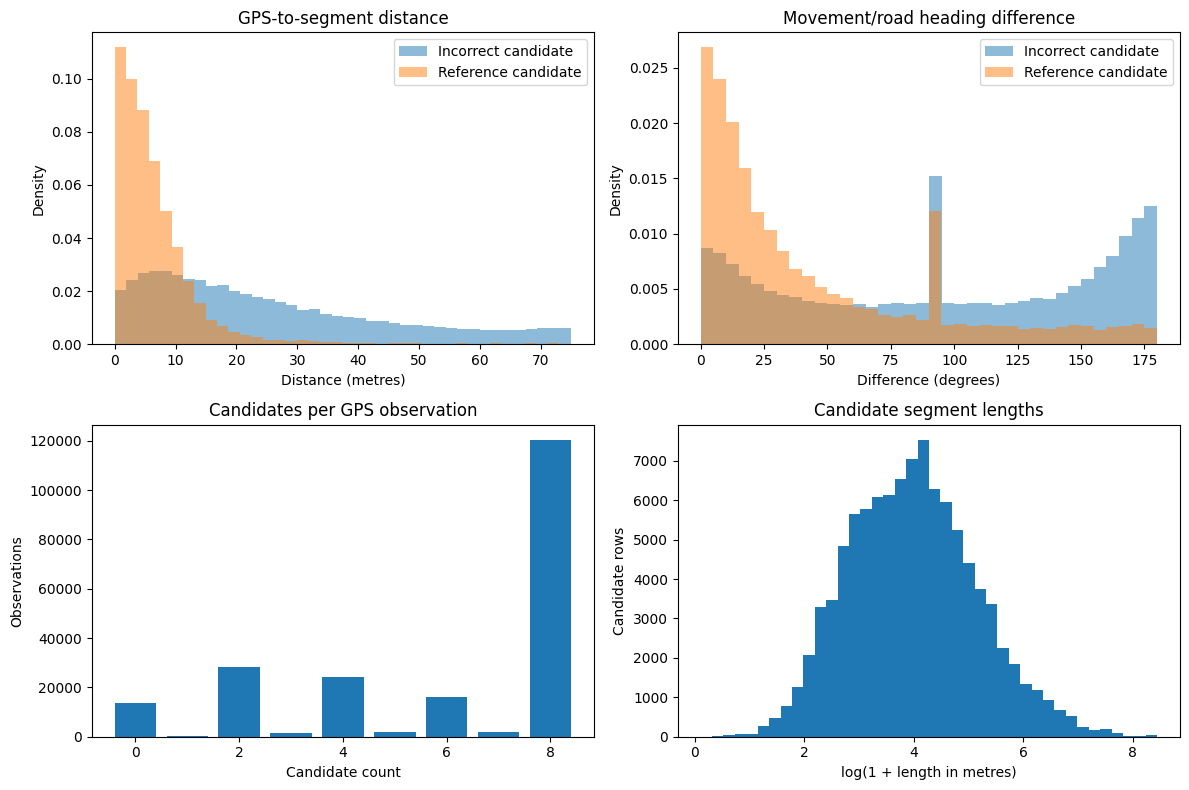

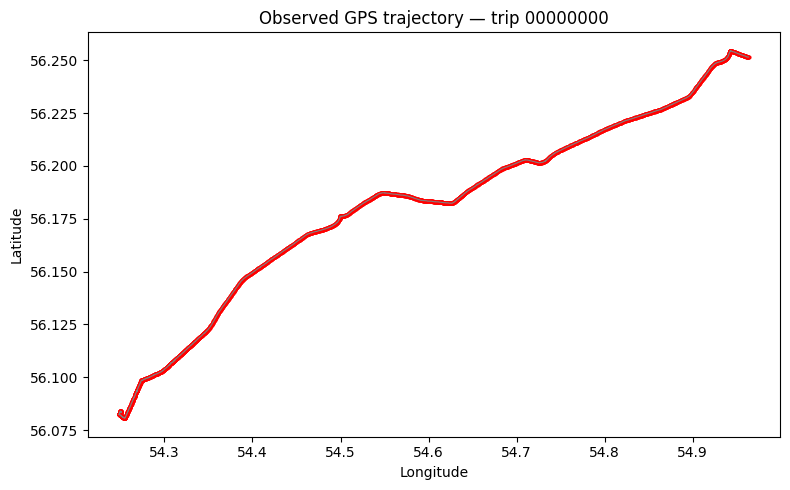

GPS-only map: original road geometry was not found at:
/content/drive/MyDrive/PathSnap_raw/Student folder/student_test/00000000
Edit RAW_DATA_ROOT to add reference and predicted road layers.


In [13]:
%pip -q install matplotlib folium

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from pathlib import Path
from sklearn.metrics import f1_score
from IPython.display import display

# Optional: original folder containing train/ and student_test/.
# Road layers require the original .nodes, .arcs and .route files.
RAW_DATA_ROOT = PROJECT_ROOT / "PathSnap_raw" / "Student folder"


# 1. Student-test results from the existing XGBoost probabilities.
student_metrics, student_matrix, student_predictions = evaluate_predictions(
    test, probabilities
)

student_metrics["Macro F1"] = f1_score(
    test.candidates.label,
    (probabilities >= 0.5).astype(int),
    average="macro",
    labels=[0, 1],
    zero_division=0,
)


# 2. Collect CV Macro F1 and actual training/validation loss histories.
# Original benchmark timings are retained in cv_metrics.
macro_rows = []
xgb_loss_histories = []
pooled_cv_matrix = np.zeros((2, 2), dtype=int)

for fold in range(1, 6):
    with np.load(
        DATA_ROOT / f"fold_{fold}_indices.npz",
        allow_pickle=False,
    ) as indices:
        fit_idx = indices["fit_idx"]
        valid_idx = indices["valid_idx"]

    assert np.array_equal(fit_idx, np.flatnonzero(row_folds != fold))
    assert np.array_equal(valid_idx, np.flatnonzero(row_folds == fold))

    fit = train.candidates.iloc[fit_idx]
    valid = train.candidates.iloc[valid_idx]
    assert not set(fit.trip_id) & set(valid.trip_id)

    valid_trips = trip_folds.index[trip_folds == fold]
    valid_data = Dataset(
        valid,
        train.observations.loc[
            train.observations.trip_id.isin(valid_trips)
        ],
    )

    fold_model = make_model()
    scaler = fold_model.named_steps["scaler"]
    estimator = fold_model.named_steps["xgboost"]

    # Validation rows use the training fold's scaler.
    X_fit = scaler.fit_transform(fit[FEATURES])
    X_valid = scaler.transform(valid[FEATURES])

    estimator.fit(
        X_fit,
        fit.label,
        eval_set=[
            (X_fit, fit.label),
            (X_valid, valid.label),
        ],
        verbose=False,
    )

    fold_probabilities = fold_model.predict_proba(valid[FEATURES])[:, 1]
    fold_predictions = (fold_probabilities >= 0.5).astype(int)

    macro_f1 = f1_score(
        valid.label,
        fold_predictions,
        average="macro",
        labels=[0, 1],
        zero_division=0,
    )

    _, fold_matrix, _ = evaluate_predictions(
        valid_data, fold_probabilities
    )

    pooled_cv_matrix += fold_matrix
    macro_rows.append({"Fold": fold, "Macro F1": macro_f1})
    xgb_loss_histories.append(estimator.evals_result())

    print(f"Fold {fold}: Macro F1 = {macro_f1:.4f}")

cv_plot = cv_metrics.drop(columns=["Macro F1"], errors="ignore").merge(
    pd.DataFrame(macro_rows),
    on="Fold",
    validate="one_to_one",
)

cv_plot_summary = cv_plot[METRICS + ["Macro F1"]].agg(["mean", "std"]).T

results_plot = pd.DataFrame([{
    "Model": "XGBoost",
    "CV Macro F1": cv_plot_summary.loc["Macro F1", "mean"],
    "CV Macro F1 SD": cv_plot_summary.loc["Macro F1", "std"],
    "Student Top-1": student_metrics["Top-1 Accuracy"],
    "Student Macro F1": student_metrics["Macro F1"],
    "CV Log Loss": cv_plot_summary.loc["Log Loss", "mean"],
    "Student Log Loss": student_metrics["Log Loss"],
}])

print("\nXGBOOST RESULTS")
display(results_plot)
display(cv_plot_summary)


# 3. CV Macro F1.
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    results_plot["Model"],
    results_plot["CV Macro F1"] * 100,
    yerr=results_plot["CV Macro F1 SD"] * 100,
    capsize=5,
    color="steelblue",
)
ax.set(
    title="CV Macro F1 — mean ± standard deviation",
    ylabel="Macro F1 (%)",
    ylim=(0, 100),
)
plt.tight_layout()
plt.show()


# 4. Student-test Top-1 and Macro F1.
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    ["Top-1 accuracy", "Macro F1"],
    [
        student_metrics["Top-1 Accuracy"] * 100,
        student_metrics["Macro F1"] * 100,
    ],
    color=["steelblue", "orange"],
)
ax.set(
    title="XGBoost student-test performance",
    ylabel="Score (%)",
    ylim=(0, 100),
)
plt.tight_layout()
plt.show()


# 5. Log Loss.
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    ["CV mean", "Student test"],
    [
        cv_plot_summary.loc["Log Loss", "mean"],
        student_metrics["Log Loss"],
    ],
    color=["steelblue", "orange"],
)
ax.set(title="Log Loss — lower is better", ylabel="Log Loss")
plt.tight_layout()
plt.show()


# 6. Performance across folds.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(cv_plot["Fold"], cv_plot["Macro F1"] * 100)
axes[0].set(
    title="XGBoost CV Macro F1",
    xlabel="Fold",
    ylabel="Macro F1 (%)",
    ylim=(0, 100),
)

axes[1].plot(
    cv_plot["Fold"],
    cv_plot["Top-1 Accuracy"] * 100,
    marker="o",
    label="Top-1 accuracy",
)
axes[1].plot(
    cv_plot["Fold"],
    cv_plot["Candidate Miss Rate"] * 100,
    marker="o",
    label="Candidate miss rate",
)
axes[1].set(
    title="Road selection and candidate coverage",
    xlabel="Fold",
    ylabel="Percent",
    ylim=(0, 100),
)
axes[1].legend()

plt.tight_layout()
plt.show()


# 7. Confusion matrices.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, matrix, title in zip(
    axes,
    [pooled_cv_matrix, student_matrix],
    ["Pooled CV confusion matrix", "Student-test confusion matrix"],
):
    matrix = np.asarray(matrix)
    ax.imshow(matrix, cmap="Blues")

    for row in range(2):
        for col in range(2):
            ax.text(
                col, row, f"{matrix[row, col]:,}",
                ha="center",
                va="center",
                color=(
                    "white"
                    if matrix[row, col] > matrix.max() / 2
                    else "black"
                ),
            )

    ax.set_xticks([0, 1], ["Incorrect", "Correct"])
    ax.set_yticks([0, 1], ["Incorrect", "Correct"])
    ax.set(
        title=title,
        xlabel="Predicted candidate class",
        ylabel="Actual candidate class",
    )

plt.tight_layout()
plt.show()


# 8. Training and validation loss curves.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for fold, history in enumerate(xgb_loss_histories, 1):
    ax = axes.flat[fold - 1]
    ax.plot(history["validation_0"]["logloss"], label="Training")
    ax.plot(history["validation_1"]["logloss"], label="Validation")
    ax.set(
        title=f"Fold {fold}",
        xlabel="Boosting round",
        ylabel="Log Loss",
    )
    ax.legend()

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


# 9. Training-data EDA.
sample = train.candidates.sample(
    n=min(100_000, len(train.candidates)),
    random_state=42,
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for label, name in [(0, "Incorrect candidate"), (1, "Reference candidate")]:
    rows = sample.loc[sample.label == label]

    axes[0, 0].hist(
        rows.distance_m,
        bins=40,
        alpha=0.5,
        density=True,
        label=name,
    )
    axes[0, 1].hist(
        rows.heading_difference_deg,
        bins=36,
        alpha=0.5,
        density=True,
        label=name,
    )

axes[0, 0].set(
    title="GPS-to-segment distance",
    xlabel="Distance (metres)",
    ylabel="Density",
)
axes[0, 0].legend()

axes[0, 1].set(
    title="Movement/road heading difference",
    xlabel="Difference (degrees)",
    ylabel="Density",
)
axes[0, 1].legend()

axes[1, 0].hist(
    train.observations.candidate_count,
    bins=np.arange(-0.5, 9.5, 1),
    rwidth=0.8,
)
axes[1, 0].set(
    title="Candidates per GPS observation",
    xlabel="Candidate count",
    ylabel="Observations",
)

axes[1, 1].hist(np.log1p(sample.segment_length_m), bins=40)
axes[1, 1].set(
    title="Candidate segment lengths",
    xlabel="log(1 + length in metres)",
    ylabel="Candidate rows",
)

plt.tight_layout()
plt.show()


# 10. Selected student-test GPS trajectory.
trip_id = sorted(test.observations.trip_id.unique())[0]
trip_obs = student_predictions.loc[
    student_predictions.trip_id == trip_id
].sort_values("timestamp")

trip_obs = trip_obs.loc[
    np.isfinite(trip_obs.latitude)
    & np.isfinite(trip_obs.longitude)
].copy()

if trip_obs.empty:
    raise ValueError("No valid GPS coordinates available for this trip.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    trip_obs.longitude,
    trip_obs.latitude,
    linewidth=0.8,
    color="gray",
)
ax.scatter(
    trip_obs.longitude,
    trip_obs.latitude,
    s=4,
    color="red",
)
ax.set(
    title=f"Observed GPS trajectory — trip {trip_id}",
    xlabel="Longitude",
    ylabel="Latitude",
)
plt.tight_layout()
plt.show()


# 11. Folium map using the working Esri satellite background.
trip_map = folium.Map(
    location=[trip_obs.latitude.mean(), trip_obs.longitude.mean()],
    zoom_start=13,
    tiles=(
        "https://services.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri, Vantor, Earthstar Geographics, and the GIS User Community",
)

gps_layer = folium.FeatureGroup(name="Observed GPS", show=True)
gps_coords = trip_obs[["latitude", "longitude"]].to_numpy().tolist()

folium.PolyLine(
    gps_coords,
    color="red",
    weight=2,
).add_to(gps_layer)

step = max(1, len(trip_obs) // 300)
for row in trip_obs.iloc[::step].itertuples():
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=2,
        color="red",
        fill=True,
        fill_opacity=0.8,
        popup=f"GPS observation {row.observation_id}",
    ).add_to(gps_layer)

gps_layer.add_to(trip_map)

trip_folder = RAW_DATA_ROOT / "student_test" / trip_id
node_path = trip_folder / f"{trip_id}.nodes"
arc_path = trip_folder / f"{trip_id}.arcs"
route_path = trip_folder / f"{trip_id}.route"

if node_path.is_file() and arc_path.is_file():
    nodes = np.loadtxt(node_path, ndmin=2)
    arcs = np.loadtxt(arc_path, dtype=int, ndmin=2)

    def add_segments(ids, name, color, weight, show=True):
        ids = np.unique(np.asarray(ids, dtype=int))

        if len(ids) and (ids.min() < 0 or ids.max() >= len(arcs)):
            raise ValueError(f"{name}: arc IDs do not match this network")

        layer = folium.FeatureGroup(name=name, show=show)

        for arc_id in ids:
            coordinates = nodes[arcs[arc_id]][:, [1, 0]].tolist()
            folium.PolyLine(
                coordinates,
                color=color,
                weight=weight,
                tooltip=f"Arc {arc_id}",
            ).add_to(layer)

        layer.add_to(trip_map)

    candidate_ids = test.candidates.loc[
        test.candidates.trip_id == trip_id, "arc_id"
    ].unique()

    add_segments(
        candidate_ids,
        "Candidate roads",
        "gray",
        1,
        show=False,
    )

    if route_path.is_file():
        reference_ids = np.loadtxt(route_path, dtype=int, ndmin=1)
        reference_name = "Supplied reference route"
    else:
        reference_ids = trip_obs.reference_arc_id.to_numpy()
        reference_name = "Derived reference segments"

    add_segments(reference_ids, reference_name, "lime", 5)

    predicted_ids = (
        trip_obs.predicted_arc_id.dropna().astype(int).to_numpy()
    )
    add_segments(
        predicted_ids,
        "XGBoost selected segments",
        "cyan",
        3,
    )

    print("Map: red = GPS, green = reference, cyan = XGBoost selections.")
else:
    print("GPS-only map: original road geometry was not found at:")
    print(trip_folder)
    print("Edit RAW_DATA_ROOT to add reference and predicted road layers.")

trip_map.fit_bounds([
    [trip_obs.latitude.min(), trip_obs.longitude.min()],
    [trip_obs.latitude.max(), trip_obs.longitude.max()],
])

folium.LayerControl().add_to(trip_map)
display(trip_map)